# Учебное исследование территории
## Кировский административный округ, Омск

**Цель.** Загрузить открытые данные OpenStreetMap, подготовить слой кварталов и рассчитать показатели городской среды с помощью библиотеки **BlocksNet 1.0.0a9** и её модуля сетей `iduedu`.

**Что делает ноутбук:**
1. Загружает границы, дороги, железные дороги и воду из OpenStreetMap.
2. Нарезает кварталы и назначает землепользование.
3. Считает время в пути между кварталами по готовому графу, в минутах.
4. Собирает здания и услуги (школы) по кварталам.
5. Считает показатели: обеспеченность школами, плотностные индикаторы, морфотипы, доступность.

**Источник данных:** OpenStreetMap (загрузка через `osmnx` и `iduedu`).
**Источник графа:** OpenStreetMap, пешеходная сеть (функция `get_accessibility_graph(..., 'walk')` из BlocksNet/IduEdu). **Способ передвижения:** пешком. **Время:** в минутах (вес рёбер `time_min`).

**Как запускать.** Откройте ноутбук в Jupyter (папка `examples`), выберите ядро `.venv` и выполняйте ячейки по порядку сверху вниз. При повторном запуске данные берутся из готовых файлов в папке `data/omsk_kirovsky`.

## 0. Настройки и импорты
Здесь задаются пути, название территории, тип графа и флаг переиспользования файлов. Значения можно менять.

In [56]:
# Базовые библиотеки
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import osmnx as ox

# --- Настройки исследования (можно менять) ---
TERRITORY_NAME = 'Кировский административный округ, Омск, Омская область, Россия'
OSM_ID = None            # если поиск по названию не сработает, укажите числовой OSM id округа
GRAPH_TYPE = 'walk'      # готовый граф: 'walk' (пешеходный) или 'drive' (автомобильный)
USE_CACHED = True        # True = брать готовые файлы, если они уже есть

# Папка для данных и результатов (лежит рядом с ноутбуком, в examples/)
DATA_DIR = Path('data') / 'omsk_kirovsky'
DATA_DIR.mkdir(parents=True, exist_ok=True)

print('Рабочая папка:', Path.cwd())
print('Папка данных:', DATA_DIR.resolve())
print('Граф:', GRAPH_TYPE, '| Переиспользовать файлы:', USE_CACHED)

Рабочая папка: c:\Users\mari1\OneDrive\Desktop\ИИ\python-package-boilerplate\examples
Папка данных: C:\Users\mari1\OneDrive\Desktop\ИИ\python-package-boilerplate\examples\data\omsk_kirovsky
Граф: walk | Переиспользовать файлы: True


In [57]:
# --- Помощники: сохранение и повторное использование файлов ---

def exists(name):
    return (DATA_DIR / name).exists()


def _to_serializable(gdf):
    geom_name = gdf.geometry.name if gdf.geometry is not None else None
    for col in gdf.columns:
        if col == geom_name:
            continue
        if gdf[col].dtype == object:
            gdf[col] = gdf[col].map(
                lambda v: v.value if hasattr(v, 'value')
                else (v if isinstance(v, (str, int, float, bool)) or v is None else str(v))
            )
    return gdf


def save_layer(gdf, name):
    # Сохраняет пространственный слой в GeoJSON (в градусах, EPSG:4326)
    path = DATA_DIR / name
    out = gdf if gdf.crs is None else gdf.to_crs(4326)
    out = _to_serializable(out.copy())
    if path.exists():
        path.unlink()
    out.to_file(path, driver='GeoJSON')
    print('Сохранено:', path)


def load_layer(name, crs=None):
    gdf = gpd.read_file(DATA_DIR / name)
    if crs is not None and gdf.crs is not None:
        gdf = gdf.to_crs(crs)
    return gdf


def save_table(df, name):
    path = DATA_DIR / name
    out = df.drop(columns='geometry') if 'geometry' in df.columns else df
    out.to_csv(path, index=True)
    print('Сохранено:', path)


def load_table(name):
    return pd.read_csv(DATA_DIR / name, index_col=0)


def save_graph(graph, name):
    # Граф сети сохраняется в формат GraphML (это не слой, а сеть)
    path = DATA_DIR / name
    ox.save_graphml(graph, filepath=path)
    print('Сохранено:', path)


def load_graph(name):
    # Возвращаем числовые типы для времени и расстояния, систему координат — в целое
    return ox.load_graphml(
        DATA_DIR / name,
        graph_dtypes={'crs': int},
        edge_dtypes={'time_min': float, 'length_meter': float},
    )


print('Помощники готовы')

Помощники готовы


## 1. Загрузка данных OpenStreetMap
### 1.1. Границы территории
Если файл уже сохранён и `USE_CACHED = True`, данные берутся из файла. Иначе — скачиваются из OpenStreetMap.

In [58]:
# Настройка альтернативного сервера Overpass для загрузки данных OSM.
# Это нужно, чтобы избежать ошибок SSL/таймаутов с сервера по умолчанию
# (https://overpass-api.de/api). osmnx сам добавит /interpreter к адресу.
OVERPASS_URL = 'https://overpass.private.coffee/api'
ox.settings.overpass_url = OVERPASS_URL
print('Сервер Overpass:', ox.settings.overpass_url)
# Если на этом сервере тоже появятся ошибки, замените OVERPASS_URL на:
#   https://overpass.kumi.systems/api

Сервер Overpass: https://overpass.private.coffee/api


Границы загружены из файла


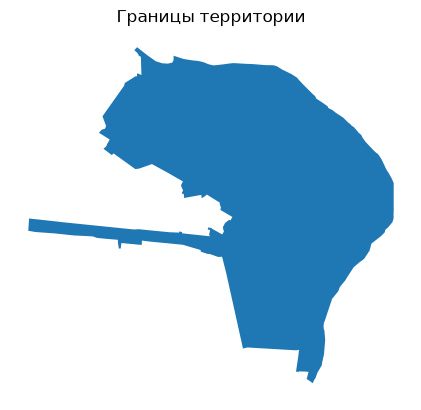

In [59]:
if USE_CACHED and exists('boundaries.geojson'):
    boundaries = load_layer('boundaries.geojson')
    print('Границы загружены из файла')
else:
    if OSM_ID is not None:
        from iduedu import get_boundary
        geom = get_boundary(osm_id=OSM_ID)
        boundaries = gpd.GeoDataFrame(geometry=[geom], crs=4326)
    else:
        boundaries = ox.geocode_to_gdf(TERRITORY_NAME)
    if len(boundaries) == 0:
        raise ValueError('Территория не найдена. Уточните TERRITORY_NAME или задайте OSM_ID.')
    save_layer(boundaries, 'boundaries.geojson')

boundaries.to_crs(4326).plot().set_axis_off()
plt.title('Границы территории')
plt.show()

In [60]:
# Теги OpenStreetMap: что именно загружаем для нарезки кварталов
bc_tags = {
    'roads': {
        'highway': ['construction', 'crossing', 'living_street', 'motorway', 'motorway_link', 'motorway_junction',
                    'pedestrian', 'primary', 'primary_link', 'raceway', 'residential', 'road', 'secondary',
                    'secondary_link', 'services', 'tertiary', 'tertiary_link', 'track', 'trunk', 'trunk_link',
                    'turning_circle', 'turning_loop', 'unclassified'],
        'service': ['living_street', 'emergency_access'],
    },
    'railways': {'railway': 'rail'},
    'water': {
        'riverbank': True, 'reservoir': True, 'basin': True, 'dock': True, 'canal': True, 'pond': True,
        'natural': ['water', 'bay'], 'waterway': ['river', 'canal', 'ditch'],
        'landuse': 'basin', 'water': 'lake',
    },
}
print('Теги заданы')

Теги заданы


In [61]:
wgs_boundary = boundaries.to_crs(4326).union_all()

# Принудительно задаём сервер Overpass перед загрузкой данных OSM.
import osmnx as ox
ox.settings.overpass_url = 'https://overpass.private.coffee/api'

if USE_CACHED and exists('water.geojson') and exists('roads.geojson') and exists('railways.geojson'):
    water = load_layer('water.geojson')
    roads = load_layer('roads.geojson')
    railways = load_layer('railways.geojson')
    print('Дороги, ж/д и вода загружены из файлов')
else:
    water = ox.features_from_polygon(wgs_boundary, bc_tags['water'])[['geometry']].copy()
    roads = ox.features_from_polygon(wgs_boundary, bc_tags['roads'])[['geometry']].copy()
    railways = ox.features_from_polygon(wgs_boundary, bc_tags['railways'])[['geometry']].copy()
    save_layer(water, 'water.geojson')
    save_layer(roads, 'roads.geojson')
    save_layer(railways, 'railways.geojson')

# Убираем мультииндекс (element, id) из объектов OpenStreetMap.
# Так roads/railways/water сразу пригодны для preprocess_urban_objects —
# даже если ниже выполнится старая версия ячейки.
roads = gpd.GeoDataFrame(geometry=roads.geometry.values, crs=roads.crs)
railways = gpd.GeoDataFrame(geometry=railways.geometry.values, crs=railways.crs)
water = gpd.GeoDataFrame(geometry=water.geometry.values, crs=water.crs)

print('Вода:', len(water), '| Дороги:', len(roads), '| Ж/д:', len(railways))

Дороги, ж/д и вода загружены из файлов
Вода: 238 | Дороги: 3347 | Ж/д: 521


In [62]:
water = water[water.geom_type.isin(['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'])].copy()
roads = roads[roads.geom_type.isin(['LineString', 'MultiLineString'])].copy()
railways = railways[railways.geom_type.isin(['LineString', 'MultiLineString'])].copy()

crs = boundaries.estimate_utm_crs()

for gdf in [water, roads, railways, boundaries]:
    gdf.to_crs(crs, inplace=True)

print('Система координат (в метрах):', crs)

Система координат (в метрах): EPSG:32643


### 1.2. Подготовка геометрий
Разбиваем объекты на линии и полигоны для нарезки кварталов.

In [63]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks
import geopandas as gpd

# Принудительно создаем новые объекты только из геометрии, полностью убирая старый индекс
roads_clean = gpd.GeoDataFrame(geometry=roads.geometry.values, crs=roads.crs)
railways_clean = gpd.GeoDataFrame(geometry=railways.geometry.values, crs=railways.crs)
water_clean = gpd.GeoDataFrame(geometry=water.geometry.values, crs=water.crs)

# Теперь передаем в функцию уже очищенные объекты
lines, polygons = preprocess_urban_objects(roads_clean, railways_clean, water_clean)
print('Линейных объектов:', len(lines), '| Полигональных:', len(polygons))

2026-10-18 03:54:31.480 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-18 03:54:31.497 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-18 03:54:31.507 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema


Линейных объектов: 3206 | Полигональных: 160


### 1.3. Нарезка кварталов
Квартал — минимальный элемент анализа территории.

Кварталы загружены из файла: 1459


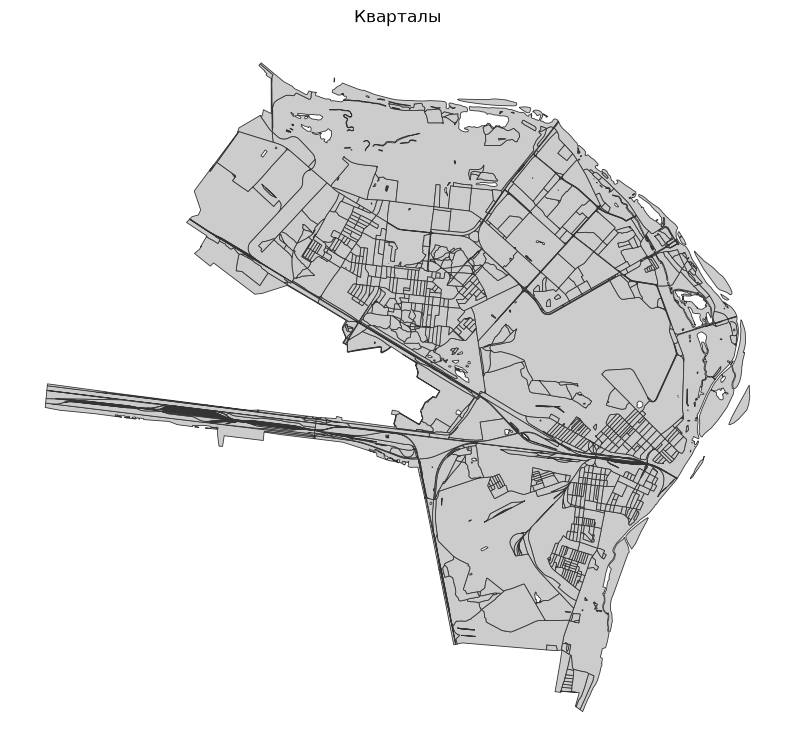

In [64]:
if USE_CACHED and exists('blocks.geojson'):
    blocks = load_layer('blocks.geojson', crs).reset_index(drop=True)
    print('Кварталы загружены из файла:', len(blocks))
else:
    blocks = cut_urban_blocks(boundaries, lines, polygons).reset_index(drop=True)
    save_layer(blocks, 'blocks.geojson')
    print('Кварталы нарезаны и сохранены:', len(blocks))

fig, ax = plt.subplots(figsize=(10, 10))
blocks.plot(ax=ax, facecolor='#cccccc', edgecolor='#333333', linewidth=0.6, alpha=1.0)
ax.set_axis_off()
ax.set_title('Кварталы')
plt.show()

## 2. Землепользование (land use)
Назначаем каждому кварталу тип землепользования по функциональным зонам OpenStreetMap.

In [65]:
# Принудительно задаём сервер Overpass перед загрузкой данных OSM.
import osmnx as ox
ox.settings.overpass_url = 'https://overpass.private.coffee/api'

if USE_CACHED and exists('functional_zones.geojson'):
    functional_zones = load_layer('functional_zones.geojson', crs)
    print('Функциональные зоны загружены из файла:', len(functional_zones))
else:
    functional_zones = ox.features_from_polygon(boundaries.to_crs(4326).union_all(), tags={'landuse': True})
    functional_zones = functional_zones.reset_index(drop=True)[['geometry', 'landuse']]
    functional_zones = functional_zones.rename(columns={'landuse': 'functional_zone'}).to_crs(crs)
    save_layer(functional_zones, 'functional_zones.geojson')
    print('Функциональные зоны скачаны:', len(functional_zones))

functional_zones.head()

Функциональные зоны загружены из файла: 1725


,functional_zone,geometry
0,garages,"POLYGON ((392557.153 6094944.578, 392561.287 6..."
1,grass,"POLYGON ((390730.903 6096738.409, 390715.55 60..."
2,grass,"POLYGON ((390523.254 6096333.497, 390530.208 6..."
3,grass,"POLYGON ((390556.238 6096257.454, 390561.842 6..."
4,construction,"POLYGON ((390814.506 6094874.989, 390747.206 6..."


In [66]:
from blocksnet.enums import LandUse

rules = {
    'commercial': LandUse.BUSINESS,
    'industrial': LandUse.INDUSTRIAL,
    'cemetery': LandUse.SPECIAL,
    'garages': LandUse.INDUSTRIAL,
    'residential': LandUse.RESIDENTIAL,
    'retail': LandUse.BUSINESS,
    'grass': LandUse.RECREATION,
    'farmland': LandUse.AGRICULTURE,
    'construction': LandUse.SPECIAL,
    'brownfield': LandUse.INDUSTRIAL,
    'forest': LandUse.RECREATION,
    'recreation_ground': LandUse.RECREATION,
    'religious': LandUse.SPECIAL,
    'flowerbed': LandUse.RECREATION,
    'military': LandUse.SPECIAL,
    'landfill': LandUse.TRANSPORT,
}
print('Правила землепользования заданы')

Правила землепользования заданы


In [67]:
from blocksnet.blocks.assignment import assign_land_use

if USE_CACHED and exists('blocks_landuse.geojson'):
    blocks = load_layer('blocks_landuse.geojson', crs).reset_index(drop=True)
    print('Кварталы с землепользованием загружены из файла')
else:
    blocks = assign_land_use(blocks, functional_zones, rules).reset_index(drop=True)
    save_layer(blocks, 'blocks_landuse.geojson')
    print('Землепользование назначено и сохранено')

blocks.head()

Кварталы с землепользованием загружены из файла


,residential,business,recreation,industrial,transport,special,agriculture,land_use,share,geometry
0,0.581466,0.022993,0.000000,0.000000,0.0,0.000000,0.003815,residential,0.581466,"POLYGON ((389919.499 6093872.97, 390054.149 60..."
1,0.000000,0.000000,0.066530,0.000000,0.0,0.000000,0.000000,recreation,0.066530,"POLYGON ((390174.854 6093617.121, 390120.846 6..."
2,0.000000,0.038732,0.018333,0.000000,0.0,0.000000,0.000000,business,0.038732,"POLYGON ((386887.38 6095734.039, 386881.77 609..."
3,0.123991,0.114501,0.031135,0.111842,0.0,0.031303,0.000000,residential,0.123991,"POLYGON ((386830.195 6095190.449, 386831.966 6..."
4,0.191248,0.000000,0.179139,0.008077,0.0,0.000000,0.000000,residential,0.191248,"POLYGON ((394343.775 6090305.072, 394338.763 6..."


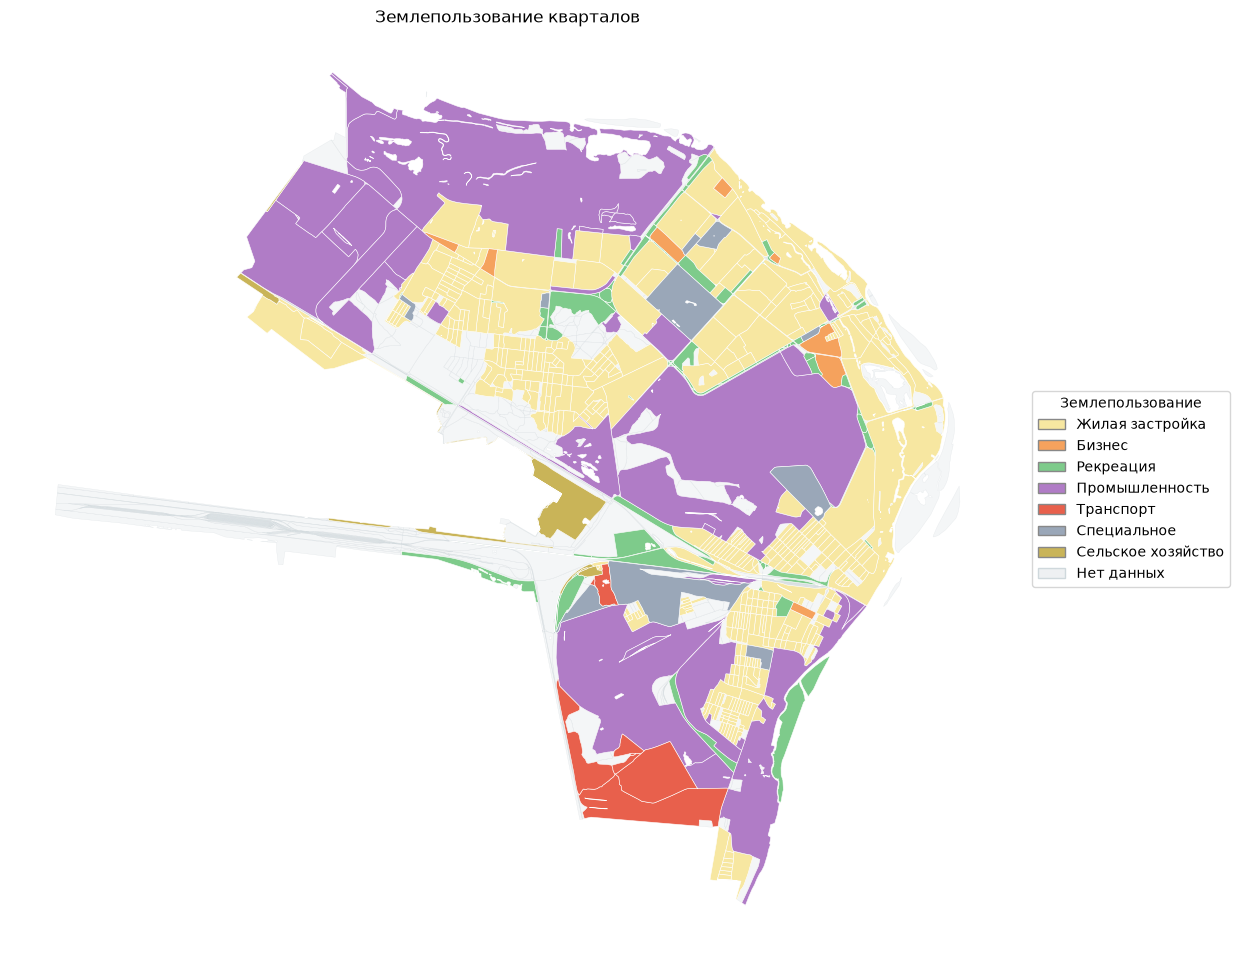

In [68]:
from matplotlib.patches import Patch

if 'land_use' in blocks.columns:
    # Технические значения enum -> понятные русские подписи
    LAND_USE_LABELS = {
        'residential': 'Жилая застройка',
        'business': 'Бизнес',
        'recreation': 'Рекреация',
        'industrial': 'Промышленность',
        'transport': 'Транспорт',
        'special': 'Специальное',
        'agriculture': 'Сельское хозяйство',
    }
    # Полное имя enum для подписи в легенде (например, LandUse.RESIDENTIAL)
    LAND_USE_ORIGINALS = {base: f'LandUse.{key.upper()}' for key, base in LAND_USE_LABELS.items()}

    def land_use_label(value):
        if pd.isna(value):
            return 'Нет данных'
        raw = getattr(value, 'value', value)
        key = str(raw).split('.')[-1].strip().lower()
        if key in ('', 'nan', 'none'):
            return 'Нет данных'
        return LAND_USE_LABELS.get(key, 'Нет данных')

    blocks['land_use_ru'] = blocks['land_use'].apply(land_use_label)

    LAND_USE_COLORS = {
        'Жилая застройка': '#f7e7a1',
        'Бизнес': '#f5a25d',
        'Рекреация': '#7ecb8b',
        'Промышленность': '#b07cc6',
        'Транспорт': '#e8604c',
        'Специальное': '#9aa7b8',
        'Сельское хозяйство': '#c9b458',
    }
    NA_COLOR = '#eef0f2'

    fig, ax = plt.subplots(figsize=(12, 10))
    ax.set_facecolor('#fbfbfb')

    # Кварталы без данных — очень светло-серые и полупрозрачные, на заднем плане
    na_blocks = blocks[blocks['land_use_ru'] == 'Нет данных']
    if len(na_blocks):
        na_blocks.plot(ax=ax, facecolor=NA_COLOR, edgecolor='#cfd8dc', linewidth=0.2, alpha=0.6)

    # Цветные кварталы по категориям — белая обводка для аккуратного вида
    for label, color in LAND_USE_COLORS.items():
        subset = blocks[blocks['land_use_ru'] == label]
        if len(subset):
            subset.plot(ax=ax, facecolor=color, edgecolor='white', linewidth=0.4)

    # Легенда вынесена справа от карты
    handles = [Patch(facecolor=LAND_USE_COLORS[l], edgecolor='#888888',
                     label=f'{l} ({LAND_USE_ORIGINALS[l]})')
               for l in LAND_USE_COLORS if (blocks['land_use_ru'] == l).any()]
    handles.append(Patch(facecolor=NA_COLOR, edgecolor='#cfd8dc', label='Нет данных'))
    ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5),
              title='Землепользование', frameon=True)

    ax.set_axis_off()
    ax.set_title('Землепользование кварталов')
    plt.tight_layout()
    plt.show()
else:
    print('Колонка land_use не найдена — сначала выполните ячейку назначения землепользования')

## ОСТАНОВКА: проверка перед расчётами
Кварталы подготовлены (границы, нарезка, землепользование). **Здесь можно остановиться и сверить список доступных метрик.**

Ниже рассчитаны все показатели из примера `pipeline.ipynb`:
- время в пути между кварталами (матрица доступности, минуты);
- агрегация зданий (население);
- агрегация услуг (школы);
- обеспеченность школами (конкурентная);
- плотностные индикаторы;
- морфотипы Spacematrix и Strelka;
- доступность по площади.

Если нужны другие услуги или метрики — сообщите, и мы дополним ноутбук. Чтобы продолжить, выполняйте ячейки ниже.

## 3. Время в пути между кварталами
### 3.1. Готовый граф
**Источник:** OpenStreetMap.
**Способ передвижения:** пешком (граф типа `walk`), загружается функцией `get_accessibility_graph`.
Интермодальный граф не строим. **Время — в минутах** (вес рёбер `time_min`).
Граф сохраняется в файл `data/omsk_kirovsky/graph_walk.graphml` и переиспользуется при повторном запуске.

In [ ]:
from blocksnet.relations import get_accessibility_graph

if USE_CACHED and exists(f'graph_{GRAPH_TYPE}.graphml'):
    graph = load_graph(f'graph_{GRAPH_TYPE}.graphml')
    print('Граф загружен из файла:', len(graph.nodes), 'узлов,', len(graph.edges), 'рёбер')
else:
    graph = get_accessibility_graph(boundaries, GRAPH_TYPE)
    save_graph(graph, f'graph_{GRAPH_TYPE}.graphml')
    print('Граф скачан из OpenStreetMap:', len(graph.nodes), 'узлов,', len(graph.edges), 'рёбер')

2026-10-18 03:57:40.604 | INFO     | iduedu.modules.drive_walk_builder:get_walk_graph:217 - Downloading walk graph from OSM, it may take a while for large territory ...


Calculating the weights of the walk graph:   0%|          | 0/67350 [00:00<?, ?it/s]

Сохранено: data\omsk_kirovsky\graph_walk.graphml
Граф скачан из OpenStreetMap: 25580 узлов, 67350 рёбер


### 3.2. Матрица доступности (время между кварталами, минуты)
Матрица показывает минимальное время в пути от центра одного квартала до центра другого.

In [ ]:
from blocksnet.relations import calculate_accessibility_matrix

if USE_CACHED and exists(f'accessibility_matrix_{GRAPH_TYPE}.csv'):
    acc_mx = load_table(f'accessibility_matrix_{GRAPH_TYPE}.csv')
    acc_mx.index = acc_mx.index.astype(int)
    acc_mx.columns = acc_mx.columns.astype(int)
    print('Матрица загружена из файла:', acc_mx.shape)
else:
    acc_mx = calculate_accessibility_matrix(blocks, graph)
    save_table(acc_mx, f'accessibility_matrix_{GRAPH_TYPE}.csv')
    print('Матрица рассчитана:', acc_mx.shape)

acc_mx.iloc[:5, :5]

## 4. Агрегация зданий
Здания задают параметры застройки: площадь, этажность, жилую площадь и население.

In [ ]:
# Принудительно задаём сервер Overpass перед загрузкой данных OSM.
import osmnx as ox
ox.settings.overpass_url = 'https://overpass.private.coffee/api'

if USE_CACHED and exists('buildings.geojson'):
    buildings = load_layer('buildings.geojson', crs)
    print('Здания загружены из файла:', len(buildings))
else:
    buildings = ox.features_from_polygon(boundaries.to_crs(4326).union_all(), tags={'building': True})
    keep = [c for c in ['geometry', 'building', 'building:levels'] if c in buildings.columns]
    buildings = buildings[keep].reset_index(drop=True).to_crs(crs)
    save_layer(buildings, 'buildings.geojson')
    print('Здания скачаны:', len(buildings))

In [ ]:
is_living_tags = ['residential', 'house', 'apartments', 'detached', 'terrace', 'dormitory']
buildings['is_living'] = buildings['building'].apply(lambda b: b in is_living_tags)

if 'building:levels' not in buildings.columns:
    buildings['building:levels'] = np.nan
buildings['number_of_floors'] = pd.to_numeric(buildings['building:levels'], errors='coerce')

buildings[['is_living', 'number_of_floors']].head()

In [ ]:
from blocksnet.preprocessing.imputing import impute_buildings

buildings = impute_buildings(buildings, default_living_demand=30)
print('Население территории (оценка):', int(buildings['population'].sum()))

In [ ]:
from blocksnet.blocks.aggregation import aggregate_objects

if USE_CACHED and exists('buildings_blocks.geojson'):
    buildings_blocks = load_layer('buildings_blocks.geojson', crs)
    print('Данные зданий по кварталам загружены из файла')
else:
    buildings_blocks = aggregate_objects(blocks, buildings)[0]
    save_layer(buildings_blocks, 'buildings_blocks.geojson')
    print('Данные зданий агрегированы по кварталам')

buildings_blocks.head()

In [ ]:
buildings_blocks.plot('population', legend=True).set_axis_off()
plt.title('Население по кварталам')
plt.show()

## 5. Агрегация услуг (школы)

In [ ]:
# Принудительно задаём сервер Overpass перед загрузкой данных OSM.
import osmnx as ox
ox.settings.overpass_url = 'https://overpass.private.coffee/api'

if USE_CACHED and exists('schools.geojson'):
    schools = load_layer('schools.geojson', crs)
    print('Школы загружены из файла:', len(schools))
else:
    schools = ox.features_from_polygon(boundaries.to_crs(4326).union_all(), tags={'amenity': 'school'})
    keep = [c for c in ['geometry', 'amenity'] if c in schools.columns]
    schools = schools[keep].reset_index(drop=True).to_crs(crs)
    save_layer(schools, 'schools.geojson')
    print('Школы скачаны:', len(schools))

In [ ]:
from blocksnet.preprocessing.imputing import impute_services

schools = impute_services(schools, 'school')
print('Мест в школах (оценка):', int(schools['capacity'].sum()))

In [ ]:
if USE_CACHED and exists('schools_blocks.geojson'):
    schools_blocks = load_layer('schools_blocks.geojson', crs)
    print('Данные школ по кварталам загружены из файла')
else:
    schools_blocks = aggregate_objects(blocks, schools)[0]
    save_layer(schools_blocks, 'schools_blocks.geojson')
    print('Данные школ агрегированы по кварталам')

schools_blocks.head()

In [ ]:
schools_blocks.plot('capacity', legend=True).set_axis_off()
plt.title('Ёмкость школ по кварталам')
plt.show()

## 6. Сводка результатов

In [ ]:
df = buildings_blocks[['population']].join(schools_blocks[['capacity']])
df.head()

In [ ]:
summary = pd.DataFrame({
    'кварталов': [len(blocks)],
    'население': [int(df['population'].sum())],
    'мест в школах': [int(df['capacity'].sum())],
    'школ': [len(schools)],
})
save_table(summary, 'results_summary.csv')
summary

## 7. Показатели (как в pipeline.ipynb)

### 7.1. Обеспеченность школами (конкурентная)

Считаем, закрывают ли школы спрос жителей. Норматив берётся из настроек BlocksNet: спрос 120 мест на 1000 жителей, доступность 15 минут. Результат — доля спроса от 0 до 1: сильная обеспеченность учитывает только школы в пределах норматива, слабая — все доступные школы.

In [ ]:
from blocksnet.config import service_types_config

school_cfg = service_types_config['school']
print(school_cfg)
_, demand, accessibility = school_cfg.values()
print('Норматив (чел. на место):', demand, '| Порог доступности (мин):', accessibility)

In [ ]:
from blocksnet.analysis.provision import competitive_provision

prov_df, links_df = competitive_provision(df, acc_mx, accessibility, demand)
prov_df.head()

#### 7.1.1. Связи кварталов и школ

`links_df` показывает, жители каких кварталов (`source`) пользуются школами каких кварталов (`target`) и сколько мест при этом занято (`value`). Это результат распределения спроса.

In [ ]:
save_table(links_df.reset_index(), 'provision_links_school.csv')
print('Связей квартал-школа:', len(links_df))
links_df.reset_index().head()

In [ ]:
save_table(prov_df, 'provision_school.csv')

ax = blocks.plot(color='#dddddd')
blocks.join(prov_df).plot('provision_strong', ax=ax, cmap='RdYlGn', vmin=0, vmax=1, legend=True)
ax.set_axis_off()
plt.title('Обеспеченность школами (сильная)')
plt.show()

### 7.2. Плотностные индикаторы

FSI — во сколько раз площадь всех этажей больше площади квартала; GSI — какая часть квартала занята зданиями; MXI — доля жилья; L — средняя этажность; OSR — сколько свободного места на единицу площади; share_living и share_non_living — доли жилья и нежилья от пятна застройки.

In [ ]:
from blocksnet.analysis.indicators import calculate_density_indicators

buildings_blocks['site_area'] = buildings_blocks.area
density_df = calculate_density_indicators(buildings_blocks)
save_table(density_df, 'density.csv')
density_df[['fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living']].head()

### 7.3. Морфотипы Spacematrix

Spacematrix группирует кварталы в кластеры по плотности и этажности и даёт каждому кластеру текстовый тип застройки.

In [ ]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes

spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
save_table(spacematrix_df, 'spacematrix.csv')
spacematrix_df.head()

#### 7.3.1. Таблица кластеров Spacematrix

Каждый кластер — группа похожих кварталов. В таблице по кластерам видны средние значения (`l`, `fsi`, `mxi`) и расшифровка: этажность, плотность и смешанность.

In [ ]:
save_table(spacematrix_clusters.reset_index(), 'spacematrix_clusters.csv')
spacematrix_clusters.head()

In [ ]:
import colorsys
from matplotlib.patches import Patch

STAGE_FRAC = {'low-rise': 0.0, 'mid-rise': 0.25, 'high-mid-rise': 0.5, 'high-rise': 0.75, 'tower': 1.0}
STAGE_RU = {
    'low-rise': 'Малоэтажная',
    'mid-rise': 'Среднеэтажная',
    'high-mid-rise': 'Многоэтажная (высокая/средняя)',
    'high-rise': 'Высотная',
    'tower': 'Башенная',
}
TYPE_RU = {'residential': 'жилая', 'mixed-use': 'смешанная', 'non-residential': 'нежилая'}
DENSITY_RU = {'low-density': 'низкой плотности', 'high-density': 'высокой плотности'}

def morphotype_label(value):
    if pd.isna(value):
        return 'Нет данных'
    tokens = str(value).split()
    stage = next((t for t in tokens if t in STAGE_FRAC), None)
    mtype = next((t for t in tokens if t in TYPE_RU), None)
    dens = next((t for t in tokens if t in DENSITY_RU), None)
    parts = [STAGE_RU[stage]] if stage else []
    if mtype:
        parts.append(TYPE_RU[mtype])
    label = ' '.join(parts) if parts else str(value)
    if dens:
        label += f' ({DENSITY_RU[dens]})'
    return label

def morphotype_color(value):
    if pd.isna(value):
        return '#e6e6e6'
    tokens = str(value).split()
    stage = next((t for t in tokens if t in STAGE_FRAC), 'low-rise')
    mtype = next((t for t in tokens if t in TYPE_RU), 'residential')
    dens = next((t for t in tokens if t in DENSITY_RU), None)
    frac = STAGE_FRAC[stage]
    if mtype == 'residential':
        hue = 0.33 + (0.78 - 0.33) * frac   # зелёный -> фиолетовый
    elif mtype == 'mixed-use':
        hue = 0.12                          # жёлто-янтарный
    else:
        hue = 0.55                          # сине-серый
    lightness = 0.72 - 0.34 * frac
    lightness += 0.05 if dens == 'low-density' else (-0.05 if dens == 'high-density' else 0)
    lightness = min(0.85, max(0.35, lightness))
    r, g, b = colorsys.hls_to_rgb(hue, lightness, 0.55)
    return '#%02x%02x%02x' % (int(r * 255), int(g * 255), int(b * 255))

sm = blocks.join(spacematrix_df[['cluster', 'morphotype']])
sm['morphotype_ru'] = sm['morphotype'].apply(morphotype_label)

present = sorted(m for m in sm['morphotype_ru'].unique() if m != 'Нет данных')
na_blocks = sm[sm['morphotype_ru'] == 'Нет данных']

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_facecolor('#fbfbfb')

if len(na_blocks):
    na_blocks.plot(ax=ax, facecolor='#e6e6e6', edgecolor='#999999', linewidth=0.3, alpha=0.6)

for label in present:
    subset = sm[sm['morphotype_ru'] == label]
    color = morphotype_color(subset['morphotype'].iloc[0])
    subset.plot(ax=ax, facecolor=color, edgecolor='black', linewidth=0.5)

originals = {label: sm[sm['morphotype_ru'] == label]['morphotype'].iloc[0] for label in present}
handles = [
    Patch(facecolor=morphotype_color(originals[label]),
          edgecolor='black', linewidth=0.5,
          label=f'{label} ({originals[label]})')
    for label in present
]
if len(na_blocks):
    handles.append(Patch(facecolor='#e6e6e6', edgecolor='#999999', label='Нет данных'))

ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5),
          title='Морфотипы', frameon=True, fontsize=9)
ax.set_axis_off()
ax.set_title('Морфотипы Spacematrix')
plt.tight_layout()
plt.show()

### 7.4. Морфотипы Strelka

In [ ]:
from blocksnet.analysis.morphotypes import get_strelka_morphotypes

strelka_df = get_strelka_morphotypes(density_df)
save_table(strelka_df, 'strelka.csv')
strelka_df.head()

In [ ]:
from matplotlib.patches import Patch

STRELKA_RU = {
    'low-rise non-residential': 'Малоэтажная нежилая',
    'individual residential': 'Индивидуальная жилая застройка',
    'low-rise model': 'Малоэтажная модель',
    'mid-rise': 'Среднеэтажная базовая',
    'mid-rise non-residential': 'Среднеэтажная нежилая',
    'mid-rise microdistrict': 'Среднеэтажный микрорайон',
    'mid-rise block': 'Среднеэтажный квартал',
    'central model': 'Центральная модель',
    'high-rise non-residential': 'Высотная нежилая',
    'high-rise soviet microdistrict': 'Высотный советский микрорайон',
    'high-rise modern microdistrict': 'Высотный современный микрорайон',
}

STRELKA_COLORS = {
    'low-rise non-residential': '#9e9e9e',
    'individual residential': '#a5d6a7',
    'low-rise model': '#66bb6a',
    'mid-rise': '#4db6ac',
    'mid-rise non-residential': '#90a4ae',
    'mid-rise microdistrict': '#64b5f6',
    'mid-rise block': '#42a5f5',
    'central model': '#ffb74d',
    'high-rise non-residential': '#7986cb',
    'high-rise soviet microdistrict': '#7e57c2',
    'high-rise modern microdistrict': '#ab47bc',
}
NA_COLOR = '#e6e6e6'
FALLBACK_COLOR = '#bdbdbd'

def strelka_label(value):
    if pd.isna(value):
        return 'Нет данных'
    orig = str(value)
    return f'{STRELKA_RU.get(orig, orig)} ({orig})'

def strelka_color(value):
    if pd.isna(value):
        return NA_COLOR
    return STRELKA_COLORS.get(str(value), FALLBACK_COLOR)

sk = blocks.join(strelka_df[['morphotype']])
sk['label'] = sk['morphotype'].apply(strelka_label)

present = [l for l in sorted(sk['label'].unique()) if l != 'Нет данных']
if (sk['label'] == 'Нет данных').any():
    present.append('Нет данных')

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_facecolor('#fbfbfb')

na_blocks = sk[sk['label'] == 'Нет данных']
if len(na_blocks):
    na_blocks.plot(ax=ax, facecolor=NA_COLOR, edgecolor='#999999', linewidth=0.3, alpha=0.6)

for label in present:
    if label == 'Нет данных':
        continue
    subset = sk[sk['label'] == label]
    color = strelka_color(subset['morphotype'].iloc[0])
    subset.plot(ax=ax, facecolor=color, edgecolor='black', linewidth=0.5)

handles = []
for label in present:
    if label == 'Нет данных':
        color = NA_COLOR
    else:
        color = strelka_color(sk[sk['label'] == label]['morphotype'].iloc[0])
    handles.append(Patch(facecolor=color, edgecolor='black', linewidth=0.5, label=label))

ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5),
          title='Морфотипы Strelka', frameon=True, fontsize=9)
ax.set_axis_off()
ax.set_title('Морфотипы Strelka')
plt.tight_layout()
plt.show()

### 7.5. Доступность по площади

In [ ]:
from blocksnet.analysis.network.accessibility import area_accessibility

area_acc = area_accessibility(acc_mx, buildings_blocks)
save_table(area_acc, 'area_accessibility.csv')
area_acc.head()

In [ ]:
blocks.join(area_acc).plot('area_accessibility', legend=True).set_axis_off()
plt.title('Доступность по площади')
plt.show()

## 8. Проверка результатов

In [ ]:
print('Кварталов:', len(blocks))
print('Форма матрицы доступности:', acc_mx.shape, '(должна быть квадратной)')
print('Кварталов с населением:', int((buildings_blocks['population'] > 0).sum()))
print('Школ:', len(schools), '| мест:', int(df['capacity'].sum()))
finite = acc_mx.replace(np.inf, np.nan)
print('Максимальное время в пути, мин:', round(float(finite.max().max()), 1))
print('Есть недостижимые пары (inf):', bool(np.isinf(acc_mx.values).any()))
print('Файлы в папке данных:')
for p in sorted(DATA_DIR.glob('*')):
    print(' -', p.name)

# Приложение. Метрики BlocksNet и показатели из pipeline.ipynb

Этот раздел — шпаргалка: он ничего не считает и данные не меняет.

## Что такое BlocksNet

BlocksNet — библиотека для анализа городской застройки по **кварталам**. Квартал — минимальная «клетка» анализа. Библиотека связывает вместе здания, сервисы (школы, больницы и т.д.), дорожную сеть и землепользование, а затем считает по каждому кварталу разные показатели.

Логика работы:
1. Нарезать город на кварталы.
2. Приложить к кварталам данные (здания, сервисы, землепользование).
3. Посчитать показатели: плотность застройки, доступность, обеспеченность услугами, морфотипы и т.д.

## 1. Какие метрики есть в BlocksNet (обзор по группам)

| Группа | Простыми словами | Примеры |
|---|---|---|
| Нарезка кварталов (`blocks.cutting`) | Делит территорию на кварталы по дорогам, воде и ж/д | `cut_urban_blocks` |
| Землепользование (`analysis.land_use`) | Какая доля территории под жильё, бизнес и т.д.; какие функции соседствуют | доли землепользования, совместное размещение (collocation), схожесть (similarity), предсказание |
| Морфотипы (`analysis.morphotypes`) | «Тип» застройки квартала: этажность, плотность, смешанность | Spacematrix, Strelka |
| Плотность застройки (`analysis.indicators.density`) | Насколько плотно и высоко застроен квартал | FSI, GSI, MXI, L, OSR |
| Индикаторы застройки (`analysis.indicators.development`) | Площади зданий и жилья, посчитанные из FSI/GSI/MXI | `build_floor_area`, `living_area`, `non_living_area` |
| Социально-экономические индикаторы (`analysis.indicators.socio_economic`) | Демография, экономика, экология, инженерия, расселение, соцсфера, транспорт | плотность населения, рождаемость, школы, дорожная плотность и др. |
| Сеть и доступность (`analysis.network`) | Время и расстояния по дорогам, связность, загрузка | матрица доступности, доступность по площади, связность, загруженность дорог |
| Обеспеченность услугами (`analysis.provision`) | Хватает ли услуг жителям по нормативу | конкурентная и общая обеспеченность |
| Сервисы (`analysis.services`) | Сколько объектов услуг, как плотно и как часто они рядом | count, density, collocation |
| Центральность (`analysis.centrality`) | Насколько квартал «центральный» по людям или услугам | `population_centrality`, `services_centrality` |
| Разнообразие (`analysis.diversity.shannon`) | Насколько разнообразны услуги в квартале | индекс Шеннона |
| Геометрия квартала (`analysis.geometry`) | Размер и форма квартала | площадь, длина, радиусы, центроиды, вытянутость |
| Свободные территории (`analysis.vacant_area`) | Пустующие, неиспользуемые участки | `get_vacant_areas` |

## 2. Показатели, которые считает pipeline.ipynb

### 2.1. Исходные слои данных

| Слой или колонка | Что это | Единицы |
|---|---|---|
| `blocks` (кварталы) | Кусочки города, разделённые дорогами и водой | геометрия |
| `land_use` | Тип землепользования квартала (жильё, бизнес, промышленность...) | категория |
| `population` | Число жителей квартала | человек |
| `footprint_area` | Площадь пятна застройки (проекция зданий на землю) | м² |
| `number_of_floors` | Число этажей здания | этажи |
| `build_floor_area` | Суммарная площадь всех этажей | м² |
| `living_area` и `non_living_area` | Площадь под жильё и не под жильё | м² |
| `is_living` | Жилое ли здание | да или нет |
| `capacity` | Вместимость сервиса (для школы — число мест) | мест |
| `acc_mx` (матрица доступности) | Сколько минут идти от каждого квартала до каждого | минуты |

### 2.2. Обеспеченность услугами (provision)

В примере считаются школы. Нормативы: спрос 120 мест на 1000 жителей, доступность 15 минут.

| Показатель | Что означает | Единицы |
|---|---|---|
| `provision_strong` | Какая доля спроса закрыта школами в пределах норматива (15 минут) — строгая обеспеченность | 0..1 |
| `provision_weak` | То же, но с учётом всех доступных школ, даже слишком далёких — мягкая обеспеченность | 0..1 |
| `demand` | Сколько мест нужно жителям квартала | мест |
| `capacity` | Сколько мест есть | мест |
| `demand_left` и `capacity_left` | Непокрытый спрос и незанятая вместимость | мест |
| `demand_within` и `capacity_within` | Спрос покрыт и вместимость использована в пределах норматива | мест |
| `demand_without` и `capacity_without` | То же, но за пределами норматива | мест |
| `links_df`: `source`, `target`, `value` | Какие кварталы пользуются какими школами и сколько мест занимают | мест |

### 2.3. Плотность застройки (density)

| Показатель | Что означает | Единицы |
|---|---|---|
| `fsi` (Floor Space Index) | Во сколько раз площадь всех этажей больше площади квартала | м²/м² (безразмерно) |
| `gsi` (Ground Space Index) | Какая часть квартала занята зданиями | 0..1 |
| `mxi` (Mixed-use Index) | Какая доля общей площади — жилая | 0..1 |
| `l` | Средняя этажность квартала | этажи |
| `osr` (Open Space Ratio) | Сколько свободного пространства на единицу площади | безразмерно |
| `share_living` и `share_non_living` | Доля жилья и нежилья от пятна застройки | безразмерно |

### 2.4. Морфотипы

| Показатель | Что означает | Единицы |
|---|---|---|
| Spacematrix `cluster` | Номер кластера похожих кварталов | число |
| Spacematrix `morphotype` | Текстовый тип застройки (например low-rise high-density) | текст |
| Strelka `morphotype` | Тип по методике Strelka: этажность, плотность, смешанность | текст |

### 2.5. Доступность

| Показатель | Что означает | Единицы |
|---|---|---|
| `area_accessibility` | Среднее время в пути от квартала до всех других, взвешенное по площади назначений | минуты |

## 3. Что всё это расскажет о Кировском округе Омска

- **Плотность (`fsi`, `gsi`, `l`)** — где застройка плотная и высокая, а где малоэтажная и свободная; где есть потенциал для уплотнения.
- **Смешанность (`mxi`)** — где преобладает жильё, а где рабочие места и коммерция; насколько кварталы «смешанные».
- **Морфотипы** — быстро разделит округ на понятные типы застройки и покажет «пятна» одинаковых районов.
- **Доступность (`acc_mx`, `area_accessibility`)** — насколько равномерно пешеходная доступность; какие кварталы «в стороне» от всего.
- **Обеспеченность школами (`provision_strong`, `provision_weak`)** — где детям не хватает мест и где школы перегружены или недогружены.
- **Землепользование** — какие функции соседствуют; где громоздкие промышленные зоны стоят рядом с жильём.

## 4. Что из BlocksNet мы пока не считаем

Наш ноутбук считает плотность, морфотипы, обеспеченность школами и доступность. При желании можно добавить:

- социально-экономические индикаторы (демография, экономика, экология, инженерия, транспорт);
- центральность (по людям и по услугам) и разнообразие услуг (индекс Шеннона);
- загруженность дорог и матрицу «источник — цель» (origin-destination);
- свободные (незастроенные) территории;
- доли и совместное размещение видов землепользования, схожесть и предсказание.

## 9. Повторный запуск

**Посмотреть результаты снова (быстро).** Выполняйте ячейки сверху вниз. При `USE_CACHED = True` ноутбук берёт готовые файлы из `data/omsk_kirovsky` и не скачивает данные заново.

**Пересчитать всё заново.** Удалите папку с данными и запустите ноутбук снова. В Windows откройте PowerShell в папке `examples` и выполните:

    Remove-Item -Recurse -Force ./data/omsk_kirovsky

**Пересчитать только часть.** Удалите нужный файл (например, `accessibility_matrix_walk.csv` или `graph_walk.graphml`) и запустите соответствующую ячейку — она пересчитает только это.

**Где результаты.** Все файлы лежат в `examples/data/omsk_kirovsky`: пространственные слои — GeoJSON, таблицы — CSV, граф — GraphML.

*Следующий этап (отдельно): Python-файл, который соберёт одну HTML-страницу с интерактивной картой и дашбордом по этим же показателям.*